In [ ]:
import pandas as pd
import numpy as np


In [ ]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
# Tangani anomali spasi kosong pada kolom TotalCharges
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

In [ ]:
# Hitung persentase Churn Rate awal perusahaan
churn_counts = df['Churn'].value_counts()
churn_rate = df['Churn'].value_counts(normalize=True) * 100

In [ ]:
print("--- Distribusi Pelanggan ---")
print(churn_counts)
print("\n--- Baseline Churn Rate ---")
print(f"Persentase Churn: {churn_rate['Yes']:.2f}%")
print(f"Persentase Retain: {churn_rate['No']:.2f}%")

--- Distribusi Pelanggan ---
Churn
No     5174
Yes    1869
Name: count, dtype: int64

--- Baseline Churn Rate ---
Persentase Churn: 26.54%
Persentase Retain: 73.46%


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Set style grafik
sns.set_theme(style="whitegrid")

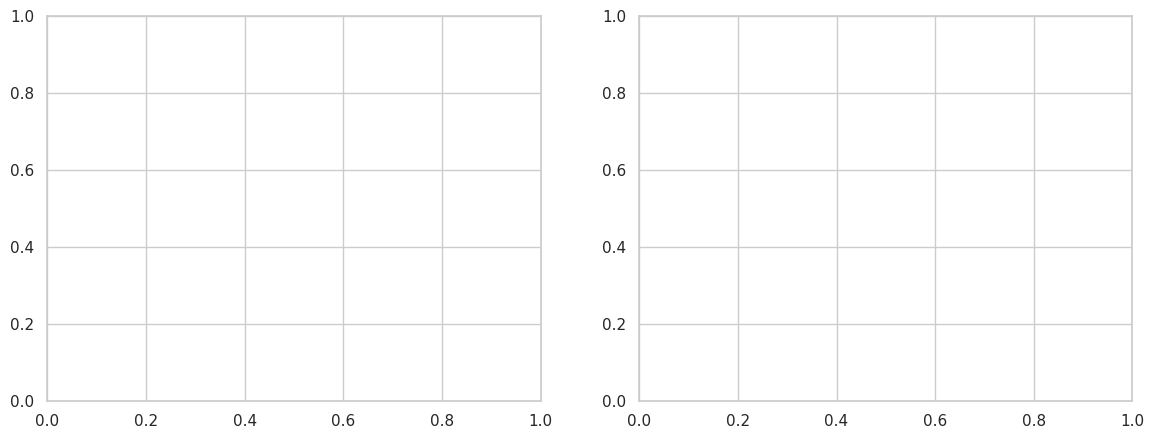

In [ ]:
# Visualisasi hubungan antara Jenis Kontrak, Masa Berlangganan (Tenure), dan Churn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

In [ ]:
# Churn berdasarkan Jenis Kontrak
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0], palette='Set2')
axes[0].set_title('Churn berdasarkan Jenis Kontrak')

Text(0.5, 1.0, 'Churn berdasarkan Jenis Kontrak')

In [ ]:
# Distribusi Tenure (Lama Berlangganan dalam Bulan)
sns.kdeplot(data=df, x='tenure', hue='Churn', common_norm=False, ax=axes[1], fill=True, palette='Set2')
axes[1].set_title('Distribusi Tenure (Bulan) terhadap Churn')

Text(0.5, 1.0, 'Distribusi Tenure (Bulan) terhadap Churn')

In [ ]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

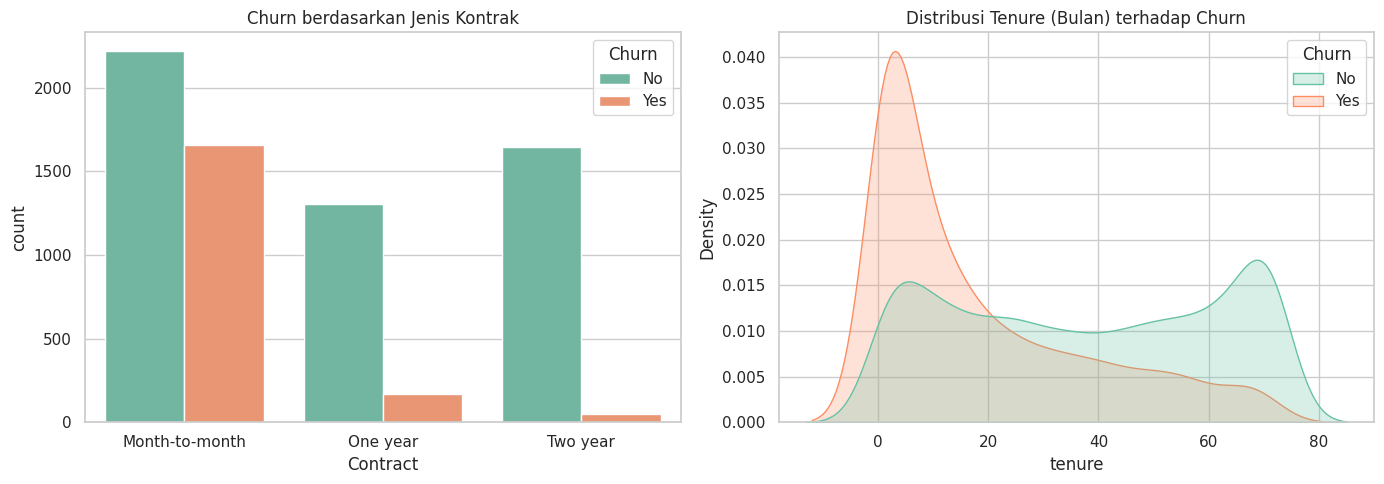

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style grafik
sns.set_theme(style="whitegrid")

# 1. Buat bingkai kanvas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 2. Grafik 1: Churn berdasarkan Jenis Kontrak
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0], palette='Set2')
axes[0].set_title('Churn berdasarkan Jenis Kontrak')

# 3. Grafik 2: Distribusi Tenure (Bulan) terhadap Churn
sns.kdeplot(data=df, x='tenure', hue='Churn', common_norm=False, ax=axes[1], fill=True, palette='Set2')
axes[1].set_title('Distribusi Tenure (Bulan) terhadap Churn')

plt.tight_layout()
plt.show()

In [ ]:
# menchine learning

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Hapus kolom ID karena tidak memiliki nilai analitis untuk prediksi
df_ml = df.drop(columns=['customerID'])

# Ubah target Churn dari teks ('Yes'/'No') menjadi angka (1/0)
df_ml['Churn'] = df_ml['Churn'].map({'Yes': 1, 'No': 0})

# Ubah seluruh kolom kategori (teks) menjadi angka otomatis (One-Hot Encoding)
df_ml = pd.get_dummies(df_ml, drop_first=True)

# Pisahkan Fitur/Variabel (X) dan Target yang ingin diprediksi (y)
X = df_ml.drop(columns=['Churn'])
y = df_ml['Churn']

# Bagi data: 80% untuk Latihan Model (Train) dan 20% untuk Ujian/Uji Performa (Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Buat dan latih model Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Tes performa model pada data uji
y_pred = rf_model.predict(X_test)

# 8. Tampilkan hasil evaluasi
print("--- Laporan Performa Model Machine Learning ---")
print(classification_report(y_test, y_pred))

--- Laporan Performa Model Machine Learning ---
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.77      0.79      0.78      1409



/tmp/ipykernel_412/2362091772.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_imp, x='Importance', y='Feature', palette='viridis')


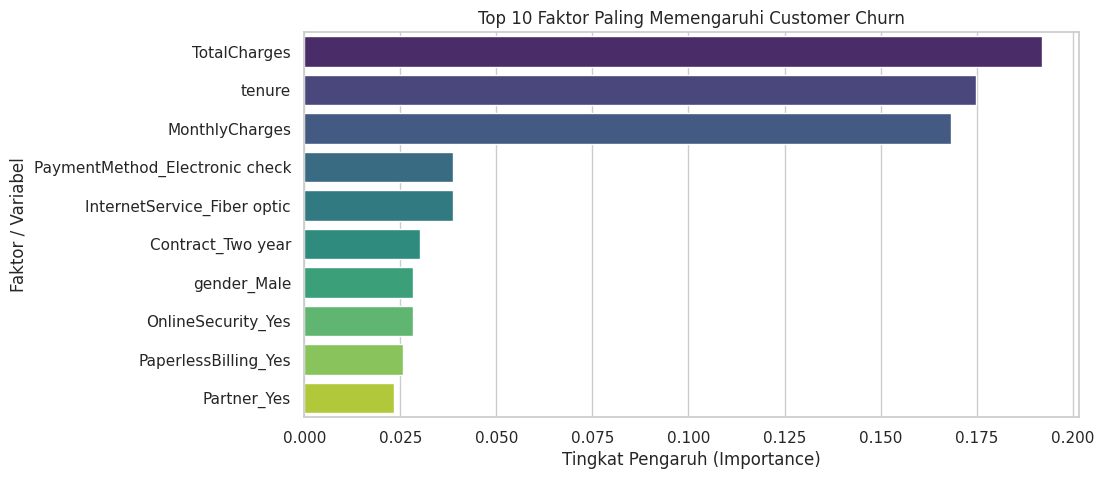

--- Selesai! File 'Telco_Churn_Predicted.csv' siap diunduh untuk Tableau. ---


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ambil tingkat kepentingan variabel dari model Random Forest
importances = rf_model.feature_importances_
feature_names = X.columns

# Ambil 10 faktor paling dominan
feature_imp = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_imp = feature_imp.sort_values('Importance', ascending=False).head(10)

# Visualisasikan faktor penentu Churn
plt.figure(figsize=(10, 5))
sns.barplot(data=feature_imp, x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Faktor Paling Memengaruhi Customer Churn')
plt.xlabel('Tingkat Pengaruh (Importance)')
plt.ylabel('Faktor / Variabel')
plt.show()

# Tambahkan prediksi skor peluang Churn (0 - 100%) ke data asli
df['Churn_Probability'] = rf_model.predict_proba(X)[:, 1]

# Ekspor data siap olah untuk Tableau
df.to_csv('Telco_Churn_Predicted.csv', index=False)
print("--- Selesai! File 'Telco_Churn_Predicted.csv' siap diunduh untuk Tableau. ---")